In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import os

folder_gambar = '/content/drive/MyDrive/PCVK/Gambar'
print('Folder ditemukan:', os.path.isdir(folder_gambar))
if os.path.isdir(folder_gambar):
    print('Isi folder:', os.listdir(folder_gambar))
else:
    print('Buat/unggah folder PCVK/Images di Google Drive, lalu jalankan sel ini lagi.')

Folder ditemukan: True
Isi folder: ['ktm_lama.jpg', '.ipynb_checkpoints', 'foto_aktivitas.jpeg', 'couple.jpg', 'KTP.jpg', 'house.jpg', 'buah.jpg', 'gedung.jpg', 'bola.jpg', 'messi_neymar.jpg', 'house_night.jpg', 'crayfish.png', 'sudoku-original.jpg', 'lena_gs_lc2.jpg', 'plat_nomer.jpg']


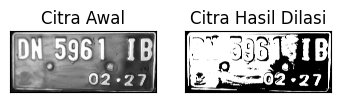

In [25]:
# Dilasi tanpa library

def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/. Periksa nama file pada output BAGIAN PEMERIKSAAN FILE.")
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


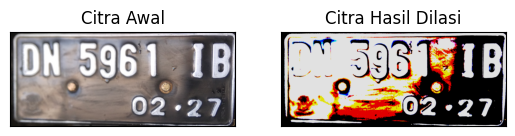

In [26]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

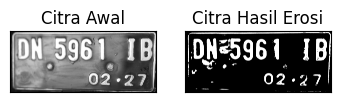

In [27]:
# Erosi Tanpa Library

def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_e is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

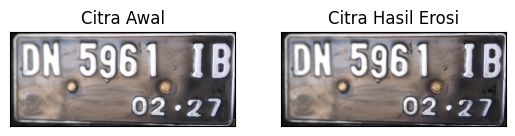

In [29]:
# EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

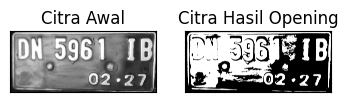

In [30]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_o is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

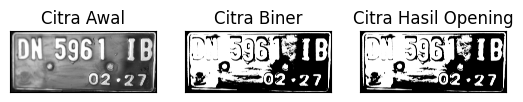

In [31]:
# Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

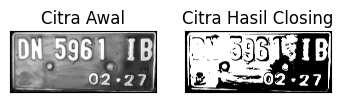

In [32]:
img_c = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_c is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

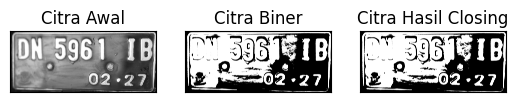

In [33]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Images/.")
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
# Dilasi Cross SED — Cross 3
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


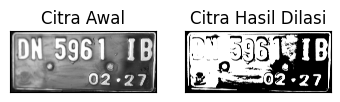

SED = Circle 5


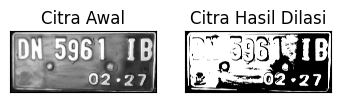

In [34]:
# Dilasi Circular SED
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 3x5


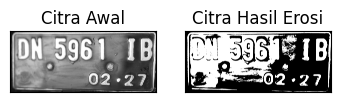

SE = Rectangle 5x7


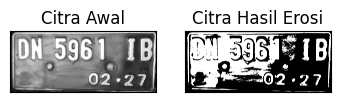

In [36]:
# Erosi Rectangle SE
def erosi_citra(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_e is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 3


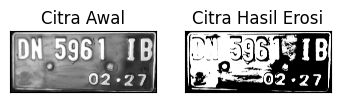

SE = Line Vertikal 5


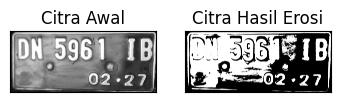

In [39]:
# Erosi Line Vertikal SE
def erosi_line_vertikal(F, k):
    m, n = F.shape
    SE = np.ones((k, 1), dtype=np.uint8)
    constant = (k - 1) // 2
    padded = cv2.copyMakeBorder(F, constant, constant, 0, 0, cv2.BORDER_CONSTANT, value=0)
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(m):
        for j in range(n):
            temp = padded[i:i+k, j:j+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_e is None:
    raise FileNotFoundError("Modul meminta gambar j.png. Letakkan j.png di folder /content/drive/MyDrive/PCVK/Gambar/ atau ubah path sesuai lokasi file.")
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_line_vertikal(thresh1, k)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
k = 5
imgE = erosi_line_vertikal(thresh1, k)
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

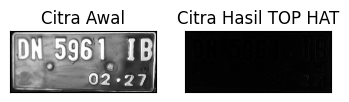

In [38]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
input_image = img

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(input_image, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

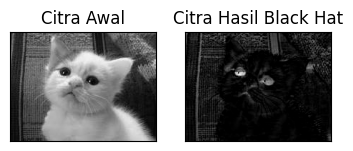

In [42]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/kitten01.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'kitten01.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

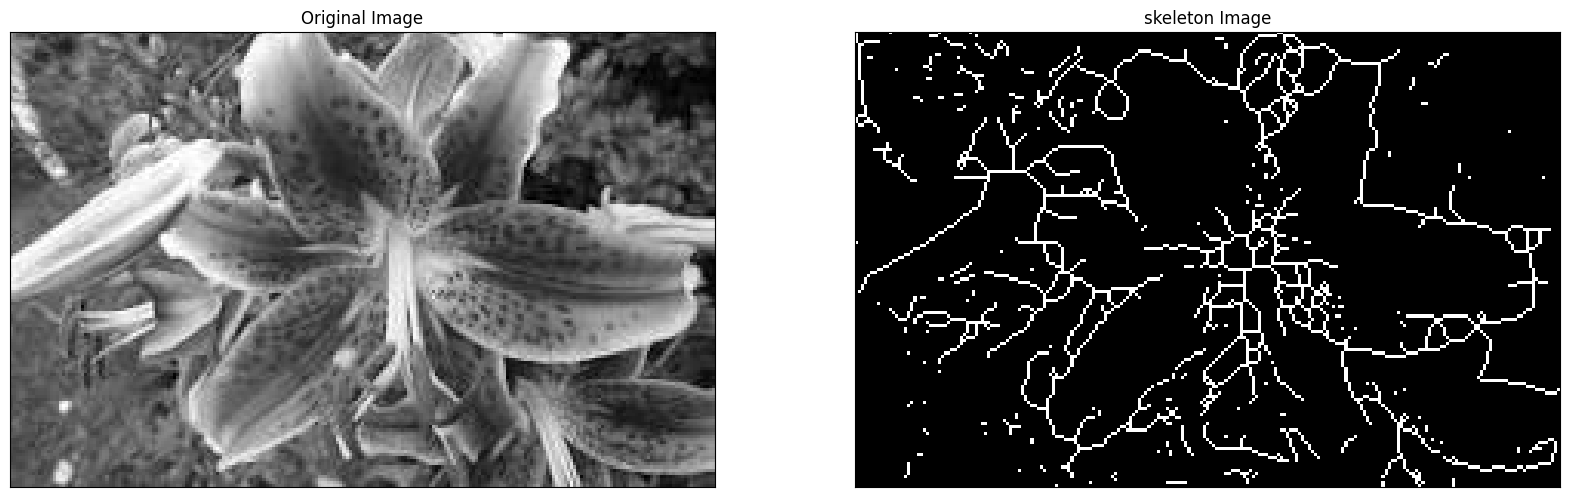

In [43]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/lily.jpg', 0)
if img is None:
    raise FileNotFoundError("Pastikan file 'lily.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary and bin_skeleton.png')
plt.show()

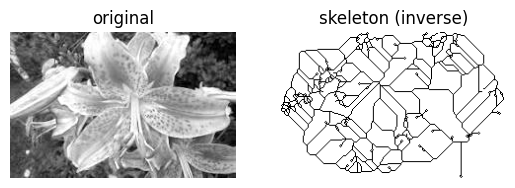

In [44]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/Gambar/lily.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'lily.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
if img.ndim == 3:
    img = img[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

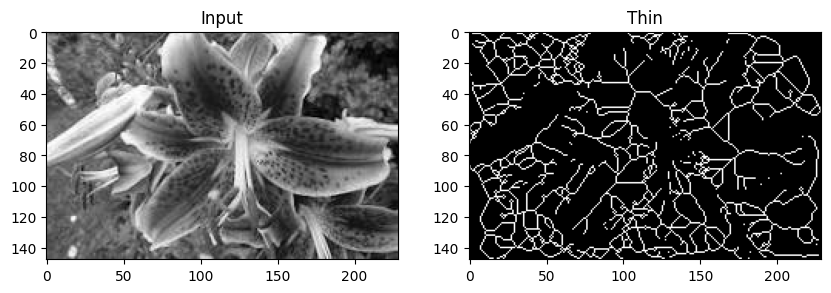

In [45]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Gambar/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

E.  Tugas Praktikum
Tugas Praktikum Morfologi melibatkan implementasi dataset KTP yang terdapat dalam
Modul 7. Dalam tugas ini, kita akan menggunakan semua informasi yang disediakan dalam
modul Morfologi dan menerapkan sejumlah nilai tambahan dalam kode sumber. Tujuannya
adalah agar citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan pada citra
tersebut.

Dilasi: memperbesar/menebalkan area objek putih.
Erosi: memperkecil/menipiskan area objek putih.
Opening: erosi dilanjutkan dilasi; membantu menghilangkan noise kecil.
Closing: dilasi dilanjutkan erosi; membantu menutup celah/lubang kecil.
Top-hat: menonjolkan detail terang kecil.
Black-hat: menonjolkan detail gelap kecil.
Skeleton: menyederhanakan objek menjadi rangka tipis.
Skeleton inverse: skeletonisasi diterapkan pada area gelap.
Pengaruh ukuran/bentuk SE: ukuran yang lebih besar biasanya memberi efek morfologi lebih kuat; bentuk SE menentukan arah/bentuk perubahan.

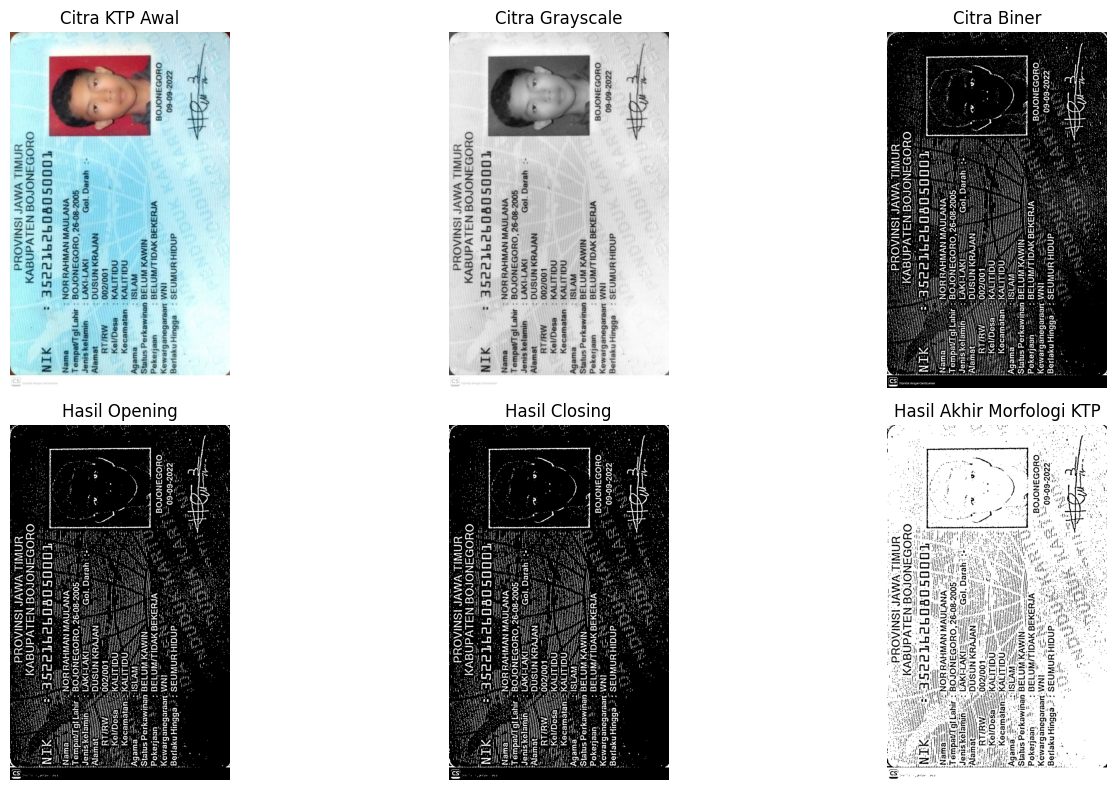

In [47]:
# BAGIAN E — TUGAS PRAKTIKUM
# Penerapan Morfologi pada Citra KTP

import cv2
import numpy as np
from matplotlib import pyplot as plt

# 1. Membaca citra KTP dari Modul 7
path_ktp = '/content/drive/MyDrive/PCVK/Gambar/KTP.jpg'
img = cv2.imread(path_ktp)

if img is None:
    raise FileNotFoundError(
        "File KTP tidak ditemukan. Sesuaikan path_ktp "
        "dengan lokasi dan nama file KTP Anda."
    )

# 2. Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Mengubah citra menjadi citra biner
binary = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    21,
    10
)

# 4. Operasi Opening untuk mengurangi noise kecil
kernel_open = np.ones((2, 2), np.uint8)
opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel_open,
    iterations=1
)

# 5. Operasi Closing untuk menyambungkan bagian
#    karakter yang terputus dan menutup celah kecil
kernel_close = np.ones((3, 2), np.uint8)
closing = cv2.morphologyEx(
    opening,
    cv2.MORPH_CLOSE,
    kernel_close,
    iterations=1
)

# 6. Mengembalikan warna teks menjadi hitam
#    dengan latar belakang putih
hasil_ktp = cv2.bitwise_not(closing)

# 7. Menampilkan hasil setiap tahapan
plt.figure(figsize=(15, 8))

plt.subplot(231)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra KTP Awal')
plt.axis('off')

plt.subplot(232)
plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(233)
plt.imshow(binary, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(234)
plt.imshow(opening, cmap='gray')
plt.title('Hasil Opening')
plt.axis('off')

plt.subplot(235)
plt.imshow(closing, cmap='gray')
plt.title('Hasil Closing')
plt.axis('off')

plt.subplot(236)
plt.imshow(hasil_ktp, cmap='gray')
plt.title('Hasil Akhir Morfologi KTP')
plt.axis('off')

plt.tight_layout()
plt.show()